In [1]:
import pandas as pd
df = pd.read_csv('Dhaka Obesity.csv')
print(df.head())

   Gender  Age  Height (m)  Weight (kg) Family history of overweight  \
0    Male   29        1.65        101.0                          Yes   
1  Female   25        1.65         53.0                           No   
2    Male   23        1.70         70.0                           No   
3    Male   22        1.68        112.0                          Yes   
4    Male   19        1.75         67.0                           No   

  High caloric food consumption Vegetable consumption frequency  \
0                           Yes                       Sometimes   
1                            No                          Always   
2                            No                          Always   
3                           Yes                       Sometimes   
4                           Yes                          Always   

  Daily main meals frequency Between-meal food consumption frequency Smoking  \
0                      Three                              Frequently      No   
1   

In [2]:
import pandas as pd

# 1. Load Dataset
df = pd.read_csv('Dhaka Obesity.csv')

# 2. Cek ringkasan awal
print("Ukuran Data:", df.shape)
print("Data Duplikat:", df.duplicated().sum())
print("Data Kosong:\n", df.isnull().sum())

Ukuran Data: (2182, 17)
Data Duplikat: 25
Data Kosong:
 Gender                                     0
Age                                        0
Height (m)                                 0
Weight (kg)                                0
Family history of overweight               0
High caloric food consumption              0
Vegetable consumption frequency            0
Daily main meals frequency                 0
Between-meal food consumption frequency    0
Smoking                                    0
Alcohol intake                             0
Daily water intake                         0
Monitor calories                           0
Physical exercise                          0
Daily device usage duration                0
Mode of transportation                     0
Obesity level                              0
dtype: int64


In [3]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder

# 1. Hapus duplikat jika ada
df = df.drop_duplicates()

# 2. Pisahkan Fitur (X) dan Target (y)
X = df.drop(columns=['Obesity level'])
y = df['Obesity level']

# 3. Ubah Target Teks ke Angka
label_enc = LabelEncoder()
y_encoded = label_enc.fit_transform(y)

# 4. Ubah Fitur Kategorikal ke Angka (One-Hot Encoding)
X_encoded = pd.get_dummies(X, drop_first=True)

# 5. Bagi Data Train (80%) & Test (20%)
X_train, X_test, y_train, y_test = train_test_split(
    X_encoded, y_encoded, test_size=0.2, random_state=42, stratify=y_encoded
)

print("Data Latih:", X_train.shape)
print("Data Uji:", X_test.shape)

Data Latih: (1725, 30)
Data Uji: (432, 30)


In [4]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report

# 1. Inisialisasi dan Latih Model
model = RandomForestClassifier(random_state=42)
model.fit(X_train, y_train)

# 2. Prediksi Data Uji
y_pred = model.predict(X_test)

# 3. Tampilkan Performa
print(f"Akurasi Model: {accuracy_score(y_test, y_pred) * 100:.2f}%\n")
print("Laporan Klasifikasi:\n", classification_report(y_test, y_pred, target_names=label_enc.classes_))

Akurasi Model: 83.33%

Laporan Klasifikasi:
                      precision    recall  f1-score   support

Insufficient_Weight       0.94      0.93      0.94        72
      Normal_Weight       0.82      0.86      0.84       106
     Obesity_Type_I       0.77      0.81      0.79        63
    Obesity_Type_II       0.85      0.79      0.82        57
   Obesity_Type_III       0.88      0.88      0.88        50
         Overweight       0.77      0.74      0.75        84

           accuracy                           0.83       432
          macro avg       0.84      0.83      0.84       432
       weighted avg       0.83      0.83      0.83       432



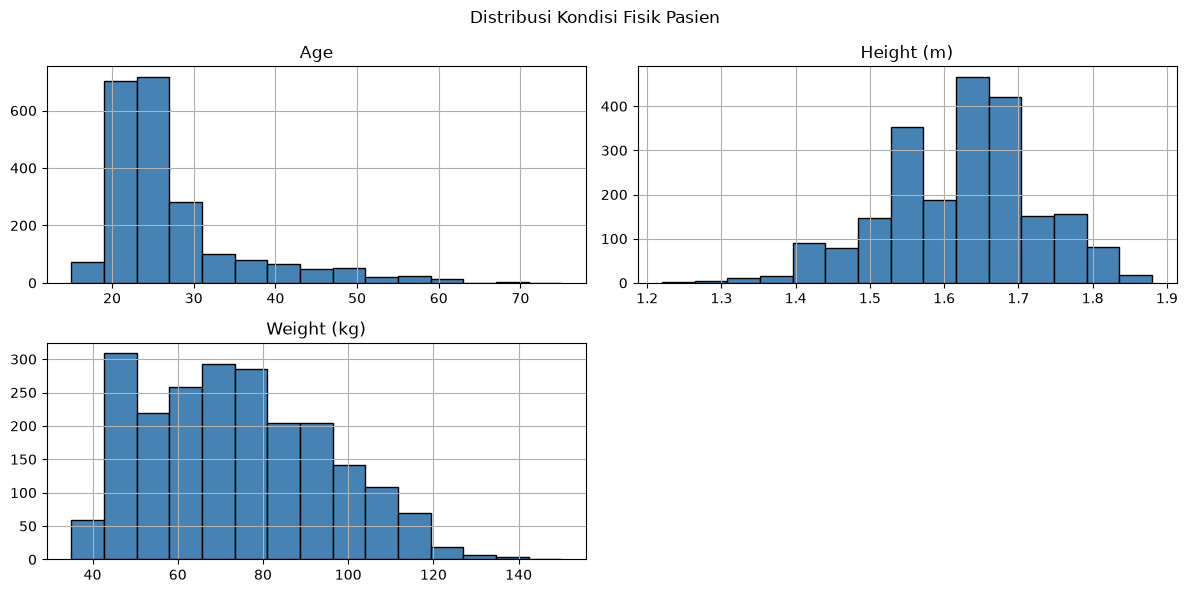

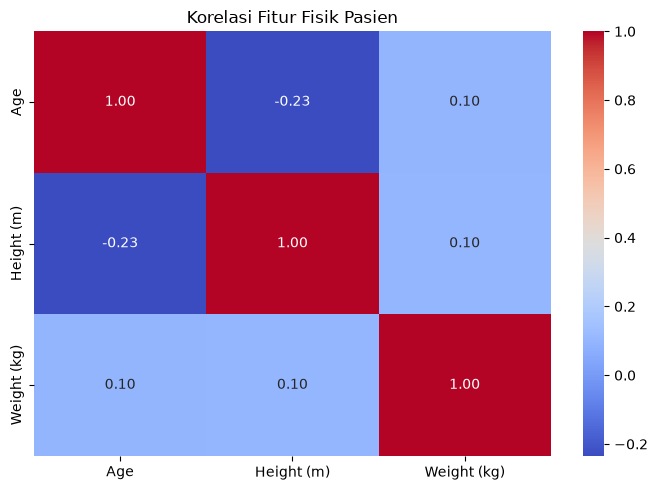

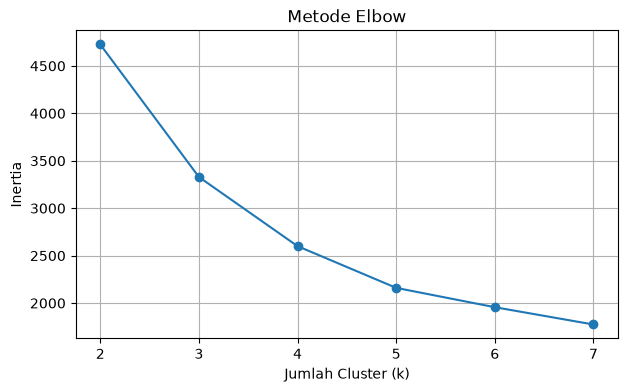

Clustering selesai.
   Age  Height (m)  Weight (kg)  Cluster
0   29        1.65        101.0        2
1   25        1.65         53.0        0
2   23        1.70         70.0        2
3   22        1.68        112.0        2
4   19        1.75         67.0        2


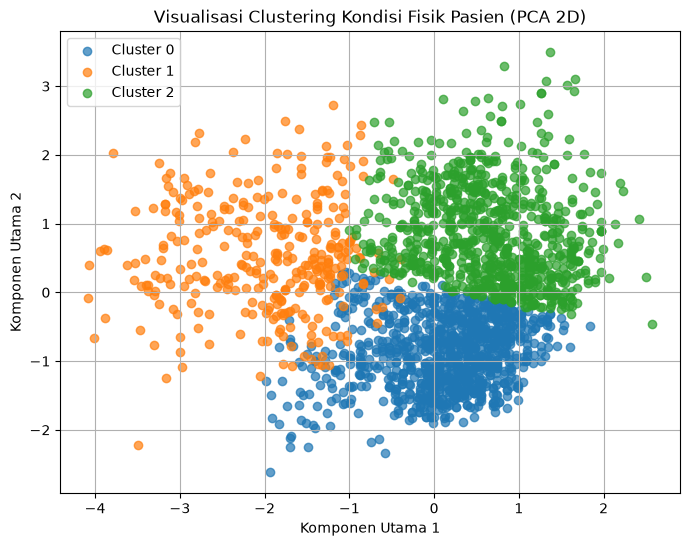

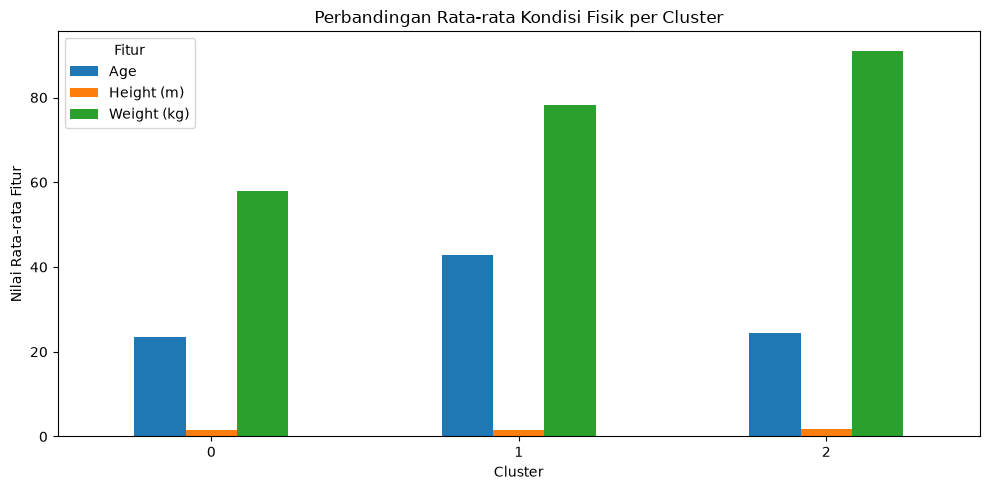

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA

# 1. LOAD DATASET
df = pd.read_csv('Dhaka Obesity.csv')

# Ambil fitur numerik untuk analisis
features = ['Age', 'Height (m)', 'Weight (kg)']
data_num = df[features].copy()

# ---------------------------------------------------------
# 2. VISUALISASI DISTRIBUSI FITUR NUMERIK
# ---------------------------------------------------------
plt.figure(figsize=(12, 6))
plt.subplot(2, 2, 1)
plt.hist(data_num['Age'], bins=15, edgecolor='black', color='steelblue')
plt.title('Age')
plt.grid(True)

plt.subplot(2, 2, 2)
plt.hist(data_num['Height (m)'], bins=15, edgecolor='black', color='steelblue')
plt.title('Height (m)')
plt.grid(True)

plt.subplot(2, 2, 3)
plt.hist(data_num['Weight (kg)'], bins=15, edgecolor='black', color='steelblue')
plt.title('Weight (kg)')
plt.grid(True)

plt.suptitle("Distribusi Kondisi Fisik Pasien")
plt.tight_layout()
plt.show()

# ---------------------------------------------------------
# 3. HEATMAP KORELASI FITUR
# ---------------------------------------------------------
plt.figure(figsize=(7, 5))
sns.heatmap(data_num.corr(), annot=True, cmap='coolwarm', fmt=".2f")
plt.title("Korelasi Fitur Fisik Pasien")
plt.tight_layout()
plt.show()

# ---------------------------------------------------------
# 4. STANDARDIZATION & METODE ELBOW (CLUSTERING)
# ---------------------------------------------------------
scaler = StandardScaler()
X_scaled = scaler.fit_transform(data_num)

inertias = []
k_values = range(2, 8)

for k in k_values:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans.fit(X_scaled)
    inertias.append(kmeans.inertia_)

plt.figure(figsize=(7, 4))
plt.plot(list(k_values), inertias, marker="o")
plt.xlabel("Jumlah Cluster (k)")
plt.ylabel("Inertia")
plt.title("Metode Elbow")
plt.xticks(list(k_values))
plt.grid(True)
plt.show()

# ---------------------------------------------------------
# 5. EXECUTE K-MEANS CLUSTERING (k = 3)
# ---------------------------------------------------------
k_terpilih = 3
kmeans = KMeans(n_clusters=k_terpilih, random_state=42, n_init=10)
data_num['Cluster'] = kmeans.fit_predict(X_scaled)

print("Clustering selesai.")
print(data_num.head())

# ---------------------------------------------------------
# 6. VISUALISASI CLUSTERING DENGAN PCA (2D SPATIAL MAP)
# ---------------------------------------------------------
pca = PCA(n_components=2)
pca_data = pca.fit_transform(X_scaled)

plt.figure(figsize=(8, 6))
for cluster in range(k_terpilih):
    plt.scatter(
        pca_data[data_num['Cluster'] == cluster, 0],
        pca_data[data_num['Cluster'] == cluster, 1],
        label=f'Cluster {cluster}',
        alpha=0.7
    )

plt.xlabel('Komponen Utama 1')
plt.ylabel('Komponen Utama 2')
plt.title('Visualisasi Clustering Kondisi Fisik Pasien (PCA 2D)')
plt.legend()
plt.grid(True)
plt.show()

# ---------------------------------------------------------
# 7. PERBANDINGAN RATA-RATA PROFIL CLUSTER
# ---------------------------------------------------------
profil_cluster = data_num.groupby('Cluster').mean()

profil_cluster.plot(kind="bar", figsize=(10, 5))
plt.title("Perbandingan Rata-rata Kondisi Fisik per Cluster")
plt.xlabel("Cluster")
plt.ylabel("Nilai Rata-rata Fitur")
plt.xticks(rotation=0)
plt.legend(title="Fitur")
plt.tight_layout()
plt.show()